## 1.

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,LogisticRegression

In [47]:
rng=np.random.default_rng(seed=42)

In [48]:
x1=rng.normal(0,0.5,(10000,2))
y1=np.zeros(10000)

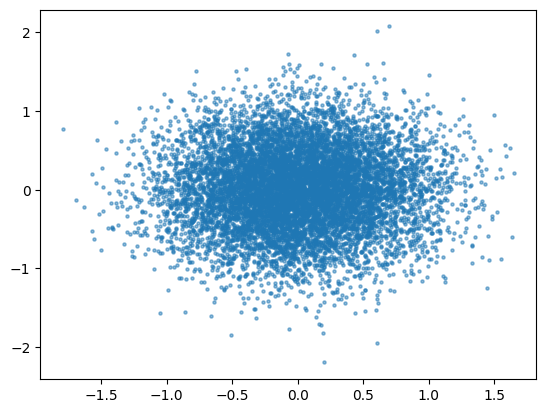

In [49]:
plt.scatter(x1[:,0],x1[:,1],s=5,alpha=0.5)
plt.show()

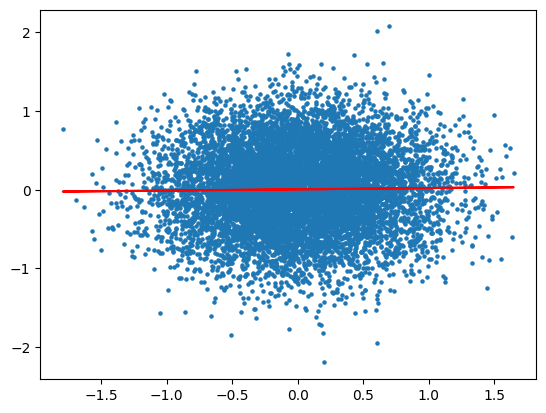

In [50]:
lr = LinearRegression()
lr.fit(x1[:, 0].reshape(-1, 1), x1[:, 1])

plt.scatter(x1[:, 0], x1[:, 1], s=5)
plt.plot(x1[:, 0], lr.predict(x1[:, 0].reshape(-1, 1)), 'r')
plt.show()

In [51]:
x2 = rng.normal(0.5, 0.1, (10000, 2))
y2 = np.ones(10000)

X = np.vstack((x1, x2))
Y = np.concatenate((y1, y2))

In [52]:
model = LogisticRegression()
model.fit(X, Y)

pred = model.predict(X)

In [53]:
for mean in np.arange(0.5, -0.05, -0.05):

    std = 0.5 - mean * 0.8

    x2 = rng.normal(mean, std, (10000, 2))
    X = np.vstack((x1, x2))
    Y = np.concatenate((y1, np.ones(10000)))

    model = LogisticRegression()
    model.fit(X, Y)
    pred = model.predict(X)

    acc = np.mean(pred == Y)
    print("Mean:", round(mean, 2), "Std:", round(std, 2),
          "Accuracy:", round(acc * 100, 2))

    if acc < 0.7:
        break

Mean: 0.5 Std: 0.1 Accuracy: 90.71
Mean: 0.45 Std: 0.14 Accuracy: 86.64
Mean: 0.4 Std: 0.18 Accuracy: 81.62
Mean: 0.35 Std: 0.22 Accuracy: 76.92
Mean: 0.3 Std: 0.26 Accuracy: 72.0
Mean: 0.25 Std: 0.3 Accuracy: 67.54


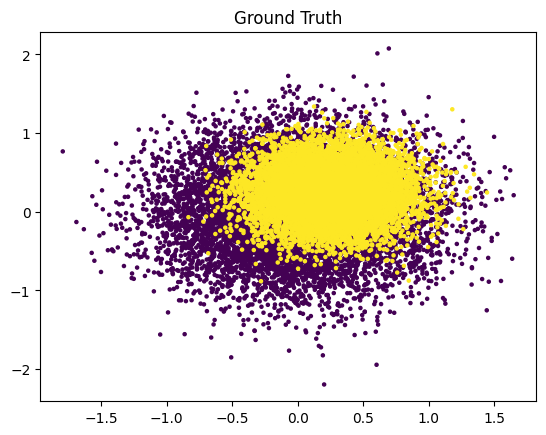

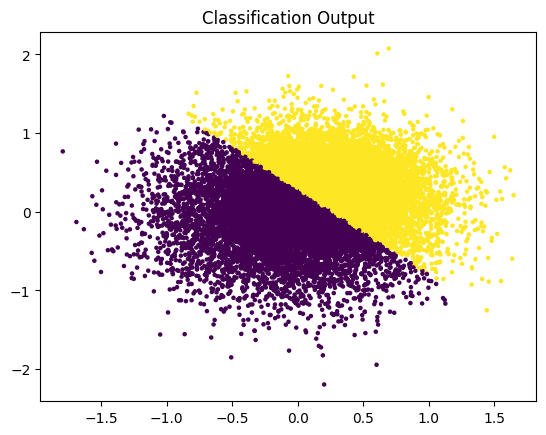

In [54]:
plt.scatter(X[:, 0], X[:, 1], c=Y, s=5)
plt.title("Ground Truth")
plt.show()

plt.scatter(X[:, 0], X[:, 1], c=pred, s=5)
plt.title("Classification Output")
plt.show()